In [7]:
# ===== BOOTSTRAP: run first after every Colab start/restart =====
import os, shutil, subprocess
from pathlib import Path
from google.colab import drive, userdata

# 1) Reconnect Google Drive (permanent storage)
drive.mount('/content/drive')

# 2) Load secrets from the Colab Secrets panel into environment variables
SECRETS = ["GITHUB_USERNAME", "GITHUB_TOKEN", "GIT_EMAIL", "DAGSHUB_USERNAME",
           "DAGSHUB_TOKEN", "KAGGLE_API_TOKEN"]
missing = []
for k in SECRETS:
    try:
        os.environ[k] = userdata.get(k)
    except Exception:
        missing.append(k)
print(f"Secrets loaded: {len(SECRETS)-len(missing)}/{len(SECRETS)}  missing: {missing or 'none'}")

# 3) Project paths
PROJECT     = "23L-0951_A2_Ops"
DRIVE       = Path("/content/drive/MyDrive")
PROJECT_DIR = DRIVE / PROJECT              # git repo (code, notebooks, small files)
WORK_DIR    = DRIVE / f"{PROJECT}_work"    # big files kept OUT of git
LOCAL_DATA  = Path("/content/data")        # fast local copy, rebuilt each session
for p in (WORK_DIR, LOCAL_DATA):
    p.mkdir(parents=True, exist_ok=True)
os.environ.update(PROJECT_DIR=str(PROJECT_DIR), WORK_DIR=str(WORK_DIR),
                  LOCAL_DATA=str(LOCAL_DATA))
os.environ["DVC_NO_ANALYTICS"] = "1"

def sh(cmd, cwd=None):
    """Run a shell command and print its output. Returns the exit code."""
    r = subprocess.run(cmd, shell=True, cwd=cwd, text=True, capture_output=True)
    out = (r.stdout + r.stderr).strip()
    if out:
        print(out)
    return r.returncode

# 4) Git settings: one credential helper per website, tokens read from env vars.
#    GitHub gets the GitHub token, DagsHub gets the DagsHub token.
#    Tokens are never saved inside the repo or in remote URLs.
gh_helper = '!f() { echo "username=${GITHUB_USERNAME}"; echo "password=${GITHUB_TOKEN}"; }; f'
dh_helper = '!f() { echo "username=${DAGSHUB_USERNAME}"; echo "password=${DAGSHUB_TOKEN}"; }; f'
subprocess.run(["git", "config", "--global", "--unset-all", "credential.helper"])  # remove old generic helper
for key, val in [("credential.https://github.com.helper", gh_helper),
                 ("credential.https://dagshub.com.helper", dh_helper),
                 ("user.name", "Zayan"),
                 ("user.email", os.environ.get("GIT_EMAIL", "")),
                 ("init.defaultBranch", "main")]:
    subprocess.run(["git", "config", "--global", key, val], check=True)

# 5) Clone the repo into Drive the first time; afterwards just pull updates
if not (PROJECT_DIR / ".git").exists():
    sh(f'git clone https://github.com/{os.environ["GITHUB_USERNAME"]}/{PROJECT}.git "{PROJECT_DIR}"')
if not (PROJECT_DIR / ".git").exists():
    raise SystemExit("Clone failed: check GITHUB_USERNAME / GITHUB_TOKEN / repo name.")
os.chdir(PROJECT_DIR)
sh("rm -f .git/index.lock")      # clears a leftover lock from a dropped session
sh("git pull --ff-only")

# 6) Reinstall pinned packages
if (PROJECT_DIR / "requirements-colab.txt").exists():
    sh("pip install -q -r requirements-colab.txt")

# 7) Helper to save a step: copy notebook into repo, commit, push
def save_step(message, notebook_name=None):
    if notebook_name:
        src = DRIVE / "Colab Notebooks" / notebook_name
        (PROJECT_DIR / "notebooks").mkdir(exist_ok=True)
        if src.exists():
            shutil.copy(src, PROJECT_DIR / "notebooks" / notebook_name)
        else:
            print("Notebook not found:", src)
    sh("git add -A")
    sh(f'git commit -m "{message}"')
    sh("git push origin main")
    sh("git log --oneline -1")

print("Bootstrap done. Working directory:", os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Secrets loaded: 6/6  missing: none
Already up to date.
Bootstrap done. Working directory: /content/drive/MyDrive/23L-0951_A2_Ops


In [8]:
import zipfile, time, random
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf, keras, mlflow

# Fast local copy of the images (rebuilt from the zip on Drive each session)
RAW_LOCAL = LOCAL_DATA / "raw"
ZIP_PATH = next((WORK_DIR / "raw_zip").glob("*.zip"))
if not (RAW_LOCAL.exists() and any(RAW_LOCAL.rglob("*.*"))):
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(RAW_LOCAL)
print("Local images:", sum(1 for p in RAW_LOCAL.rglob("*") if p.is_file()))

# MLflow -> DagsHub, credentials from Colab Secrets via environment variables
os.environ["MLFLOW_TRACKING_URI"]      = f"https://dagshub.com/{os.environ['DAGSHUB_USERNAME']}/{PROJECT}.mlflow"
os.environ["MLFLOW_TRACKING_USERNAME"] = os.environ["DAGSHUB_USERNAME"]
os.environ["MLFLOW_TRACKING_PASSWORD"] = os.environ["DAGSHUB_TOKEN"]
mlflow.set_tracking_uri(os.environ["MLFLOW_TRACKING_URI"])

# Folders for checkpoints/tuner results on Drive (survive disconnects)
CKPT_DIR  = WORK_DIR / "checkpoints"; CKPT_DIR.mkdir(exist_ok=True)
TUNER_DIR = WORK_DIR / "tuner";       TUNER_DIR.mkdir(exist_ok=True)
FIG_DIR   = PROJECT_DIR / "reports" / "figures"

SEED = 42
keras.utils.set_random_seed(SEED)       # seeds Python, NumPy and TensorFlow together
print("TF", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

Local images: 975
TF 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
%%writefile src/data.py
"""
VisionGuard input pipeline (Task 2.1).

decode_and_resize() is shared by training and the Flask app, so both
apply exactly the same preprocessing. Models receive pixels in 0..255
and normalise internally, so serving cannot use the wrong scaling.
"""
from pathlib import Path

import pandas as pd
import tensorflow as tf
import keras

IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE
CLASS_NAMES = {0: "real", 1: "ai"}

AUG_SETTINGS = {
    "mild":   dict(rotation=0.05, zoom=0.10, contrast=0.10),
    "strong": dict(rotation=0.15, zoom=0.25, contrast=0.25),
}


def decode_and_resize(raw_bytes, img_size=IMG_SIZE):
    """Encoded image bytes -> uint8 tensor (img_size, img_size, 3).

    - decode_image handles JPEG/PNG/GIF/WEBP/BMP; channels=3 converts
      grayscale and drops alpha; expand_animations=False takes a GIF's first frame.
    - resize_with_pad keeps the aspect ratio and fills the rest with black
      (letterboxing) instead of stretching the image.
    """
    img = tf.io.decode_image(raw_bytes, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize_with_pad(img, img_size, img_size, antialias=True)
    return tf.cast(tf.clip_by_value(tf.round(img), 0, 255), tf.uint8)


def load_image(path, img_size=IMG_SIZE):
    return decode_and_resize(tf.io.read_file(path), img_size)


def make_augmenter(strength="mild", seed=42):
    """Random augmentation for TRAINING only. Returns None for 'none'."""
    if strength == "none":
        return None
    s = AUG_SETTINGS[strength]
    return keras.Sequential([
        keras.layers.RandomFlip("horizontal", seed=seed),
        keras.layers.RandomRotation(s["rotation"], fill_mode="constant", seed=seed),
        keras.layers.RandomZoom(s["zoom"], fill_mode="constant", seed=seed),
        keras.layers.RandomContrast(s["contrast"], seed=seed),
    ], name=f"augment_{strength}")


def read_split(split_csv, data_root):
    df = pd.read_csv(split_csv)
    paths = [str(Path(data_root) / p) for p in df["rel_path"]]
    return paths, df["label"].astype("int32").tolist(), df


def make_dataset(split_csv, data_root, training, img_size=IMG_SIZE,
                 batch_size=BATCH_SIZE, augment="mild", seed=42):
    """Split list -> batched, prefetched tf.data.Dataset of (images 0..255 float32, labels)."""
    paths, labels, _ = read_split(split_csv, data_root)
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    # 1) read + decode + resize, in parallel
    ds = ds.map(lambda p, y: (load_image(p, img_size), y), num_parallel_calls=AUTOTUNE)
    # 2) cache decoded uint8 images in RAM: decoding happens only once
    ds = ds.cache()
    # 3) shuffle training data only; new order every epoch
    if training:
        ds = ds.shuffle(len(paths), seed=seed, reshuffle_each_iteration=True)
    # 4) batch, then convert to float for the model
    ds = ds.batch(batch_size)
    ds = ds.map(lambda x, y: (tf.cast(x, tf.float32), tf.cast(y, tf.float32)),
                num_parallel_calls=AUTOTUNE)
    # 5) augmentation on training batches only (never on val/test, never inside the saved model)
    aug = make_augmenter(augment, seed) if training else None
    if aug is not None:
        ds = ds.map(lambda x, y: (aug(x, training=True), y), num_parallel_calls=AUTOTUNE)
    # 6) prefetch: prepare the next batch while the GPU trains on the current one
    return ds.prefetch(AUTOTUNE)

Writing src/data.py


In [9]:
import importlib, sys
sys.path.insert(0, str(PROJECT_DIR))
import src.data as data; importlib.reload(data)

SPLITS = PROJECT_DIR / "data" / "splits"
train_ds = data.make_dataset(SPLITS / "train.csv", RAW_LOCAL, training=True)
val_ds   = data.make_dataset(SPLITS / "val.csv",   RAW_LOCAL, training=False)
test_ds  = data.make_dataset(SPLITS / "test.csv",  RAW_LOCAL, training=False)

print("Element spec:", train_ds.element_spec)
for name, ds in [("train", train_ds), ("val", val_ds), ("test", test_ds)]:
    print(f"{name:5s}: {sum(1 for _ in ds)} batches")

# Show the effect of caching: the 1st pass decodes from disk, the 2nd reads from RAM
for i in (1, 2):
    t = time.time(); n = sum(int(x.shape[0]) for x, _ in train_ds)
    print(f"Pass {i}: {n} images in {time.time()-t:.1f}s")

Element spec: (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.float32, name=None))
train: 22 batches
val  : 5 batches
test : 5 batches
Pass 1: 681 images in 1.0s
Pass 2: 681 images in 1.0s


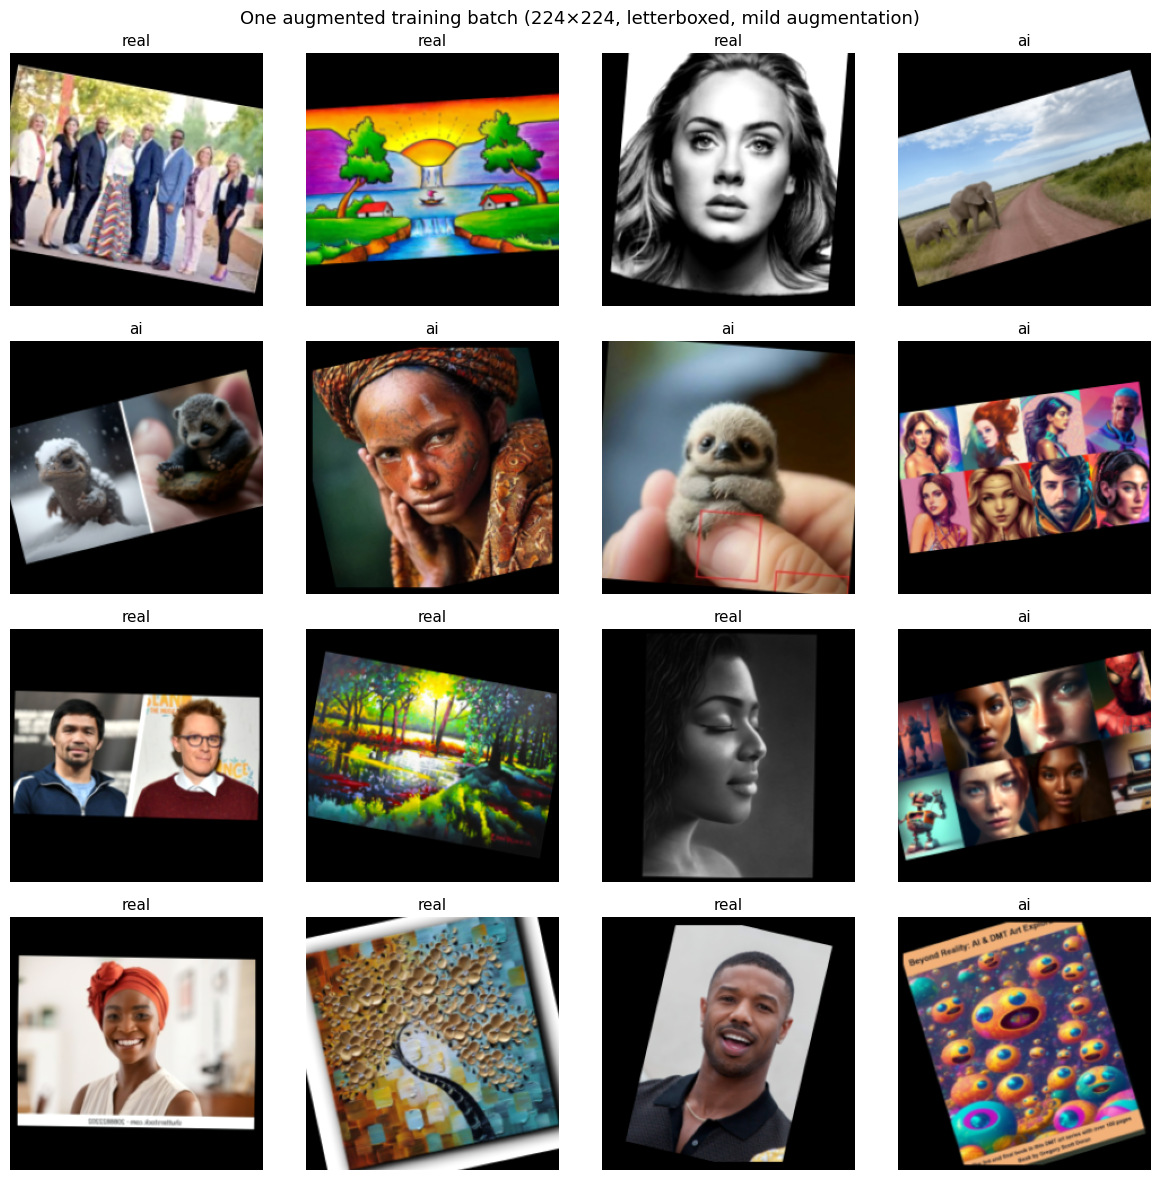

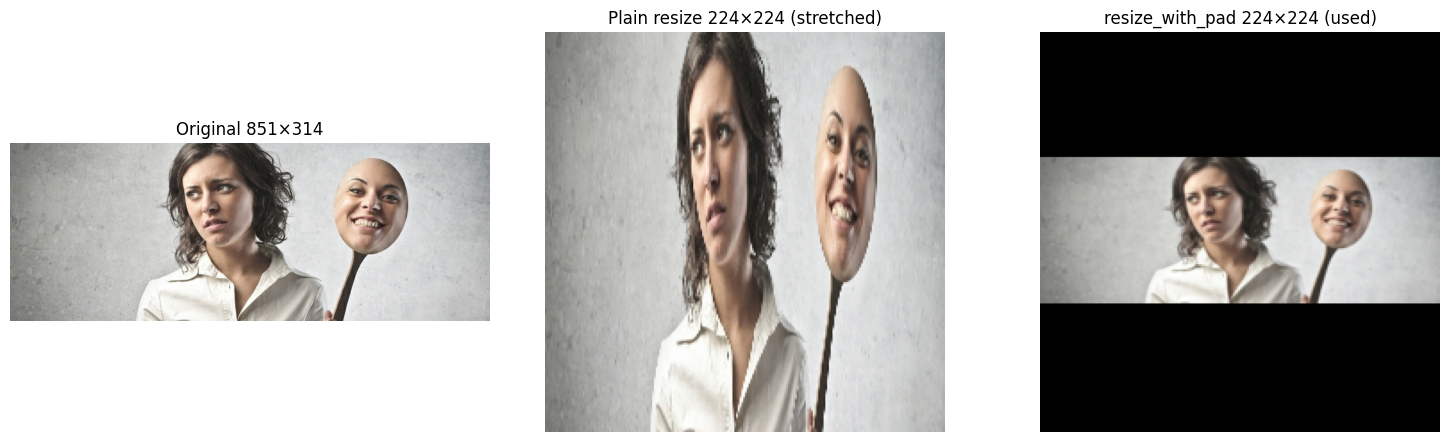

In [5]:
# Figure 1: one augmented training batch
images, labels = next(iter(train_ds))
fig, axes = plt.subplots(4, 4, figsize=(12, 12))
for ax, img, y in zip(axes.flat, images[:16], labels[:16]):
    ax.imshow(np.clip(img.numpy() / 255.0, 0, 1))
    ax.set_title(data.CLASS_NAMES[int(y)], fontsize=11)
    ax.axis("off")
fig.suptitle("One augmented training batch (224×224, letterboxed, mild augmentation)", fontsize=13)
fig.tight_layout()
fig.savefig(FIG_DIR / "pipeline_augmented_batch.png", dpi=110, bbox_inches="tight")
plt.show()

# Figure 2: what happens to aspect ratio (original vs stretch vs letterbox)
from PIL import Image
audit = pd.read_csv("reports/audit/audit_table.csv")
wide = audit[audit.readable].assign(ar=lambda d: d.width / d.height).sort_values("ar").iloc[-5]
raw = tf.io.read_file(str(RAW_LOCAL / wide.rel_path))
orig = tf.io.decode_image(raw, channels=3, expand_animations=False)
stretched = tf.cast(tf.image.resize(orig, (224, 224)), tf.uint8)
padded = data.decode_and_resize(raw)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, im, title in zip(axes, [orig, stretched, padded],
                         [f"Original {int(wide.width)}×{int(wide.height)}",
                          "Plain resize 224×224 (stretched)",
                          "resize_with_pad 224×224 (used)"]):
    ax.imshow(im.numpy()); ax.set_title(title); ax.axis("off")
fig.tight_layout()
fig.savefig(FIG_DIR / "pipeline_aspect_ratio.png", dpi=110, bbox_inches="tight")
plt.show()

In [6]:
save_step("Step 10: tf.data input pipeline + figures (Task 2.1)", "03_training.ipynb");

[main a44b780] Step 10: tf.data input pipeline + figures (Task 2.1)
 4 files changed, 84 insertions(+)
 create mode 100644 notebooks/03_training.ipynb
 create mode 100644 reports/figures/pipeline_aspect_ratio.png
 create mode 100644 reports/figures/pipeline_augmented_batch.png
 create mode 100644 src/data.py
To https://github.com/bhatti-zayan/23L-0951_A2_Ops.git
   a66cf5d..a44b780  main -> main
a44b780 Step 10: tf.data input pipeline + figures (Task 2.1)


In [10]:
import json, yaml
from mlflow.models import infer_signature
from keras import layers, callbacks

EXPERIMENT = "23L-0951_A2_Ops_visionguard"
mlflow.set_experiment(EXPERIMENT)
RUN_IDS_FILE = PROJECT_DIR / "reports" / "run_ids.json"

def git_info():
    run = lambda c: subprocess.run(c, shell=True, capture_output=True, text=True, cwd=PROJECT_DIR).stdout.strip()
    return run("git rev-parse HEAD"), bool(run("git status --porcelain"))

def dvc_data_version():
    return yaml.safe_load((PROJECT_DIR / "data" / "raw.dvc").read_text())["outs"][0]["md5"]

def base_tags(model_type, logging_mode):
    commit, dirty = git_info()
    gpu = tf.config.list_physical_devices("GPU")
    return {"git_commit": commit, "git_dirty": str(dirty),
            "dvc_data_version": dvc_data_version(), "seed": str(SEED),
            "model_type": model_type, "logging": logging_mode, "student": "23L-0951",
            "gpu": tf.config.experimental.get_device_details(gpu[0]).get("device_name") if gpu else "none"}

class ManualMlflowLogger(keras.callbacks.Callback):
    """Manual logging: after every epoch send all Keras metrics + current LR to MLflow."""
    def on_epoch_end(self, epoch, logs=None):
        logs = {k: float(v) for k, v in (logs or {}).items()}
        logs["lr"] = float(keras.ops.convert_to_numpy(self.model.optimizer.learning_rate))
        mlflow.log_metrics(logs, step=epoch + 1)          # step = 1-based epoch number

def make_callbacks(tag, es_patience=8, lr_patience=3):
    return [
        callbacks.EarlyStopping(monitor="val_loss", patience=es_patience,
                                restore_best_weights=True, verbose=1),
        callbacks.ModelCheckpoint(str(CKPT_DIR / f"{tag}_best.keras"), monitor="val_loss",
                                  save_best_only=True),
        callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=lr_patience,
                                    min_lr=1e-6, verbose=1),
        callbacks.CSVLogger(str(CKPT_DIR / f"{tag}_history.csv")),
    ]

def plot_curves(h, title, filename):
    """Loss + accuracy curves with the best epoch (lowest val_loss) marked."""
    ep = np.arange(1, len(h["loss"]) + 1)
    best = int(np.argmin(h["val_loss"])) + 1
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for ax, key in zip(axes, ["loss", "accuracy"]):
        ax.plot(ep, h[key], "o-", ms=3, label=f"train {key}")
        ax.plot(ep, h[f"val_{key}"], "o-", ms=3, label=f"val {key}")
        ax.axvline(best, color="red", ls="--", label=f"best epoch = {best}")
        ax.set_xlabel("epoch"); ax.set_ylabel(key); ax.legend(); ax.grid(alpha=.3)
    fig.suptitle(title); fig.tight_layout()
    fig.savefig(FIG_DIR / filename, dpi=110, bbox_inches="tight")
    return fig, best

def log_common_artifacts():
    mlflow.log_artifacts(str(PROJECT_DIR / "data" / "splits"), artifact_path="splits")
    mlflow.log_artifact(str(PROJECT_DIR / "reports" / "environment" / "pip-freeze-colab.txt"), "environment")
    mlflow.log_artifact(str(PROJECT_DIR / "requirements-colab.txt"), "environment")

def log_keras_model(model, tag, sample_batch):
    sig = infer_signature(sample_batch.numpy(), model.predict(sample_batch, verbose=0))
    mlflow.keras.log_model(model, name="model", signature=sig)    # MLflow model (Logged Models page)
    path = CKPT_DIR / f"{tag}_final.keras"; model.save(path)
    mlflow.log_artifact(str(path), artifact_path="model_file")    # plain file (Artifacts tab)

def save_run_id(key, run_id):
    ids = json.loads(RUN_IDS_FILE.read_text()) if RUN_IDS_FILE.exists() else {}
    ids[key] = run_id; RUN_IDS_FILE.write_text(json.dumps(ids, indent=2))

METRICS = lambda: [keras.metrics.BinaryAccuracy(name="accuracy"), keras.metrics.AUC(name="auc"),
                   keras.metrics.Precision(name="precision"), keras.metrics.Recall(name="recall")]
print("Experiment:", EXPERIMENT, "| DVC data version:", dvc_data_version())

2026/11/06 09:48:34 INFO mlflow.tracking.fluent: Experiment with name '23L-0951_A2_Ops_visionguard' does not exist. Creating a new experiment.


Experiment: 23L-0951_A2_Ops_visionguard | DVC data version: b2cec67839f742df4653f66d4bcbbafb.dir


In [11]:
def build_cnn(img_size=224, filters=(32, 64, 128, 256), dropout=0.5):
    inputs = keras.Input((img_size, img_size, 3), name="image_0_255")
    x = layers.Rescaling(1.0 / 255, name="rescale_0_1")(inputs)
    for i, f in enumerate(filters, start=1):
        x = layers.Conv2D(f, 3, padding="same", use_bias=False, name=f"conv{i}")(x)
        x = layers.BatchNormalization(name=f"bn{i}")(x)
        x = layers.ReLU(name=f"relu{i}")(x)
        x = layers.MaxPooling2D(2, name=f"pool{i}")(x)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(dropout, name="dropout")(x)
    outputs = layers.Dense(1, activation="sigmoid", name="p_ai")(x)
    return keras.Model(inputs, outputs, name="visionguard_cnn")

keras.utils.set_random_seed(SEED)
cnn = build_cnn()
cnn.summary()

layer_table = pd.DataFrame([{"layer": l.name, "type": type(l).__name__,
                             "output_shape": str(tuple(l.output.shape)),
                             "params": l.count_params()} for l in cnn.layers])
display(layer_table)
layer_table.to_csv(PROJECT_DIR / "reports" / "cnn_layer_table.csv", index=False)
print("Total params:", cnn.count_params())

Model: "visionguard_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image_0_255 (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale_0_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 224, 224, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (ReLU)                    │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 112, 112, 64)   │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (ReLU)                    │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 56, 56, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3 (ReLU)                    │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4 (Conv2D)                  │ (None, 28, 28, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn4 (BatchNormalization)        │ (None, 28, 28, 256)    │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu4 (ReLU)                    │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool4 (MaxPooling2D)            │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ p_ai (Dense)                    │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 390,113 (1.49 MB)

 Trainable params: 389,153 (1.48 MB)

 Non-trainable params: 960 (3.75 KB)

,layer,type,output_shape,params
0,image_0_255,InputLayer,"(None, 224, 224, 3)",0
1,rescale_0_1,Rescaling,"(None, 224, 224, 3)",0
2,conv1,Conv2D,"(None, 224, 224, 32)",864
3,bn1,BatchNormalization,"(None, 224, 224, 32)",128
4,relu1,ReLU,"(None, 224, 224, 32)",0
5,pool1,MaxPooling2D,"(None, 112, 112, 32)",0
6,conv2,Conv2D,"(None, 112, 112, 64)",18432
7,bn2,BatchNormalization,"(None, 112, 112, 64)",256
8,relu2,ReLU,"(None, 112, 112, 64)",0
9,pool2,MaxPooling2D,"(None, 56, 56, 64)",0


Total params: 390113


Epoch 1/40
22/22 - 32s - 1s/step - accuracy: 0.5609 - auc: 0.5787 - loss: 0.7892 - precision: 0.5919 - recall: 0.6596 - val_accuracy: 0.5479 - val_auc: 0.5866 - val_loss: 0.6826 - val_precision: 0.5564 - val_recall: 0.9136 - learning_rate: 0.0010
Epoch 2/40
22/22 - 2s - 96ms/step - accuracy: 0.5786 - auc: 0.6060 - loss: 0.7454 - precision: 0.6093 - recall: 0.6596 - val_accuracy: 0.5548 - val_auc: 0.6129 - val_loss: 0.6834 - val_precision: 0.5548 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 3/40
22/22 - 2s - 96ms/step - accuracy: 0.6256 - auc: 0.6555 - loss: 0.6864 - precision: 0.6547 - recall: 0.6809 - val_accuracy: 0.5479 - val_auc: 0.5953 - val_loss: 0.6828 - val_precision: 0.5540 - val_recall: 0.9506 - learning_rate: 0.0010
Epoch 4/40

Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
22/22 - 2s - 95ms/step - accuracy: 0.6300 - auc: 0.6722 - loss: 0.6737 - precision: 0.6498 - recall: 0.7154 - val_accuracy: 0.5548 - val_auc: 0.6226 - val_loss: 0.6902 -

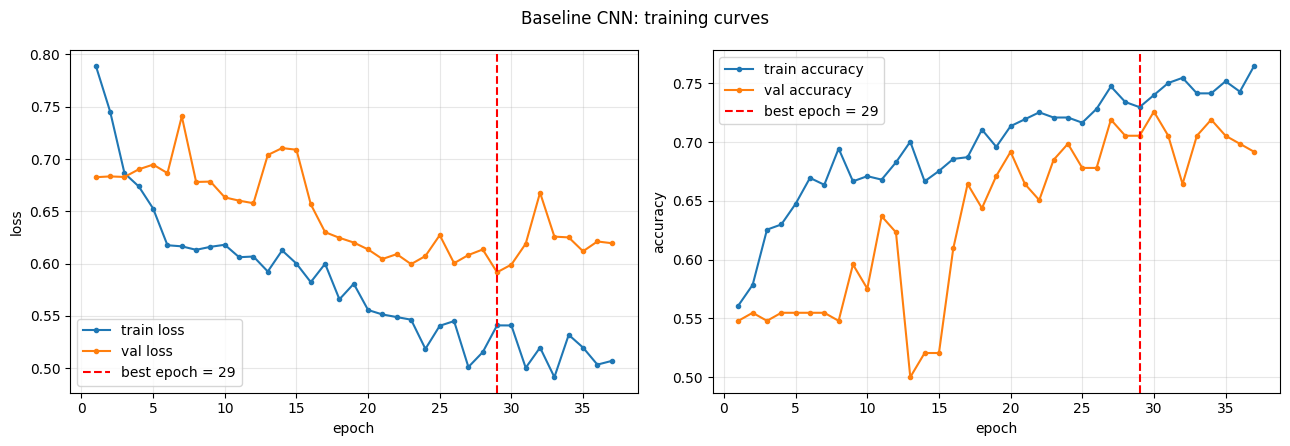


Best epoch: 29 | best val_loss: 0.5917 | run_id: 2e262f2bf3a54cbc889058ee0fa2e0b8
🏃 View run cnn_baseline_manual at: https://dagshub.com/bhatti-zayan/23L-0951_A2_Ops.mlflow/#/experiments/1/runs/2e262f2bf3a54cbc889058ee0fa2e0b8
🧪 View experiment at: https://dagshub.com/bhatti-zayan/23L-0951_A2_Ops.mlflow/#/experiments/1


In [12]:
TAG, EPOCHS, LR = "cnn_baseline", 40, 1e-3
keras.utils.set_random_seed(SEED)
cnn = build_cnn()
cnn.compile(optimizer=keras.optimizers.Adam(LR), loss="binary_crossentropy", metrics=METRICS())

params = {"model": "baseline_cnn", "img_size": 224, "batch_size": 32, "learning_rate": LR,
          "max_epochs": EPOCHS, "optimizer": "adam", "loss": "binary_crossentropy",
          "augmentation": "mild", "dropout": 0.5, "filters": "32-64-128-256",
          "early_stopping_patience": 8, "reduce_lr_patience": 3, "resize": "pad_224"}

with mlflow.start_run(run_name="cnn_baseline_manual") as run:
    mlflow.set_tags(base_tags("baseline_cnn", "manual_callback"))
    mlflow.log_params(params)
    hist = cnn.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, verbose=2,
                   callbacks=make_callbacks(TAG) + [ManualMlflowLogger()])

    fig, best = plot_curves(hist.history, "Baseline CNN: training curves", "cnn_baseline_curves.png")
    mlflow.log_figure(fig, "curves/cnn_baseline_curves.png"); plt.show()
    mlflow.log_metrics({"best_epoch": best, "best_val_loss": float(min(hist.history["val_loss"])),
                        "epochs_trained": len(hist.history["loss"])})
    log_common_artifacts()
    sample, _ = next(iter(val_ds))
    log_keras_model(cnn, TAG, sample[:4])
    save_run_id(TAG, run.info.run_id)
    print(f"\nBest epoch: {best} | best val_loss: {min(hist.history['val_loss']):.4f} | run_id: {run.info.run_id}")

In [13]:
save_step("Step 11: baseline CNN with callbacks + manual MLflow logging (2.2, 2.4, 3.3)", "03_training.ipynb");

[main e0a1dc4] Step 11: baseline CNN with callbacks + manual MLflow logging (2.2, 2.4, 3.3)
 4 files changed, 26 insertions(+), 1 deletion(-)
 create mode 100644 reports/cnn_layer_table.csv
 create mode 100644 reports/figures/cnn_baseline_curves.png
 create mode 100644 reports/run_ids.json
To https://github.com/bhatti-zayan/23L-0951_A2_Ops.git
   a44b780..e0a1dc4  main -> main
e0a1dc4 Step 11: baseline CNN with callbacks + manual MLflow logging (2.2, 2.4, 3.3)


In [14]:
from keras.applications import MobileNetV2, mobilenet_v2

def build_mobilenet(img_size=224, dropout=0.3):
    base = MobileNetV2(include_top=False, weights="imagenet", input_shape=(img_size, img_size, 3))
    base.trainable = False
    inputs = keras.Input((img_size, img_size, 3), name="image_0_255")
    # Identical to mobilenet_v2.preprocess_input: x / 127.5 - 1  ->  [-1, 1]
    x = layers.Rescaling(1 / 127.5, offset=-1.0, name="mobilenet_preprocess")(inputs)
    x = base(x, training=False)           # BatchNorm stays in inference mode
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(dropout, name="dropout")(x)
    outputs = layers.Dense(1, activation="sigmoid", name="p_ai")(x)
    return keras.Model(inputs, outputs, name="visionguard_mobilenetv2"), base

def unfreeze_last_block(base, first_layer="block_16_expand"):
    base.trainable = True                  # must come first: it switches ALL sub-layers on
    start = [l.name for l in base.layers].index(first_layer)
    for i, l in enumerate(base.layers):
        l.trainable = (i >= start) and not isinstance(l, layers.BatchNormalization)

def trainable_layers(model, base):
    names = ([f"mobilenetv2/{l.name}" for l in base.layers if l.trainable and l.trainable_weights]
             if base.trainable else [])
    names += [l.name for l in model.layers if l is not base and l.trainable_weights]
    n = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
    return names, n

# Proof that our Rescaling layer == the preprocessing MobileNetV2 expects
sample, _ = next(iter(val_ds))
ours = layers.Rescaling(1 / 127.5, offset=-1.0)(sample).numpy()
official = mobilenet_v2.preprocess_input(sample.numpy().copy())
print("Max difference vs mobilenet_v2.preprocess_input:", float(np.abs(ours - official).max()))

keras.utils.set_random_seed(SEED)
model, base = build_mobilenet()
model.summary(show_trainable=True)
print("Backbone layers:", len(base.layers))

Max difference vs mobilenet_v2.preprocess_input: 1.1920928955078125e-07
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "visionguard_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ image_0_255 (InputLayer)    │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ mobilenet_preprocess        │ (None, 224, 224, 3)   │          0 │   -   │
│ (Rescaling)                 │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ mobilenetv2_1.00_224        │ (None, 7, 7, 1280)    │  2,257,984 │   N   │
│ (Functional)                │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ gap                         │ (None, 1280)          │          0 │   -   │
│ (GlobalAveragePooling2D)    │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout (Dropout)           │ (None, 1280)          │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ p_ai (Dense)                │ (None, 1)             │      1,281 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Backbone layers: 154


Epoch 1/20


22/22 - 37s - 2s/step - accuracy: 0.5389 - auc: 0.5401 - loss: 0.8149 - precision: 0.5752 - recall: 0.6303 - val_accuracy: 0.5822 - val_auc: 0.5996 - val_loss: 0.7112 - val_precision: 0.6316 - val_recall: 0.5926 - learning_rate: 0.0010
Epoch 2/20


22/22 - 4s - 188ms/step - accuracy: 0.6021 - auc: 0.6362 - loss: 0.6923 - precision: 0.6350 - recall: 0.6569 - val_accuracy: 0.6301 - val_auc: 0.6924 - val_loss: 0.6369 - val_precision: 0.6484 - val_recall: 0.7284 - learning_rate: 0.0010
Epoch 3/20


22/22 - 4s - 173ms/step - accuracy: 0.6740 - auc: 0.7142 - loss: 0.6208 - precision: 0.7026 - recall: 0.7101 - val_accuracy: 0.6644 - val_auc: 0.7417 - val_loss: 0.5958 - val_precision: 0.6778 - val_recall: 0.7531 - learning_rate: 0.0010
Epoch 4/20
22/22 - 1s - 62ms/step - accuracy: 0.6652 - auc: 0.7306 - loss: 0.6138 - precision: 0.6713 - recall: 0.7713 - val_accuracy: 0.7123 - val_auc: 0.7669 - val_loss: 0.5966 - val_precision: 0.8000 - val_recall: 0.6420 - learning_rate: 0.0010
Epoch 5/20


22/22 - 4s - 169ms/step - accuracy: 0.6902 - auc: 0.7700 - loss: 0.5680 - precision: 0.7027 - recall: 0.7606 - val_accuracy: 0.7055 - val_auc: 0.7835 - val_loss: 0.5564 - val_precision: 0.7500 - val_recall: 0.7037 - learning_rate: 0.0010
Epoch 6/20


22/22 - 9s - 405ms/step - accuracy: 0.7342 - auc: 0.7993 - loss: 0.5413 - precision: 0.7546 - recall: 0.7686 - val_accuracy: 0.6918 - val_auc: 0.7979 - val_loss: 0.5450 - val_precision: 0.6915 - val_recall: 0.8025 - learning_rate: 0.0010
Epoch 7/20


... (7 outputs left out)

22/22 - 19s - 848ms/step - accuracy: 0.8194 - auc: 0.8994 - loss: 0.4068 - precision: 0.8139 - recall: 0.8723 - val_accuracy: 0.7534 - val_auc: 0.8272 - val_loss: 0.5049 - val_precision: 0.7848 - val_recall: 0.7654 - learning_rate: 1.2500e-04
Restoring model weights from the end of the best epoch: 20.
1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step
🏃 View run stage1_frozen at: https://dagshub.com/bhatti-zayan/23L-0951_A2_Ops.mlflow/#/experiments/1/runs/a29d4b8234284963994ea160852f0501
🧪 View experiment at: https://dagshub.com/bhatti-zayan/23L-0951_A2_Ops.mlflow/#/experiments/1


Epoch 1/20


22/22 - 26s - 1s/step - accuracy: 0.8091 - auc: 0.8837 - loss: 0.4270 - precision: 0.8170 - recall: 0.8431 - val_accuracy: 0.7329 - val_auc: 0.8287 - val_loss: 0.5057 - val_precision: 0.7386 - val_recall: 0.8025 - learning_rate: 1.0000e-05
Epoch 2/20
22/22 - 1s - 63ms/step - accuracy: 0.8194 - auc: 0.9017 - loss: 0.3993 - precision: 0.8186 - recall: 0.8644 - val_accuracy: 0.7466 - val_auc: 0.8303 - val_loss: 0.5060 - val_precision: 0.7973 - val_recall: 0.7284 - learning_rate: 1.0000e-05
Epoch 3/20


22/22 - 4s - 191ms/step - accuracy: 0.8561 - auc: 0.9281 - loss: 0.3560 - precision: 0.8639 - recall: 0.8777 - val_accuracy: 0.7466 - val_auc: 0.8303 - val_loss: 0.5002 - val_precision: 0.7750 - val_recall: 0.7654 - learning_rate: 1.0000e-05
Epoch 4/20
22/22 - 1s - 63ms/step - accuracy: 0.8150 - auc: 0.9071 - loss: 0.3852 - precision: 0.8189 - recall: 0.8537 - val_accuracy: 0.7671 - val_auc: 0.8317 - val_loss: 0.5051 - val_precision: 0.8133 - val_recall: 0.7531 - learning_rate: 1.0000e-05
Epoch 5/20

Epoch 5: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
22/22 - 1s - 66ms/step - accuracy: 0.8414 - auc: 0.9167 - loss: 0.3723 - precision: 0.8490 - recall: 0.8670 - val_accuracy: 0.7603 - val_auc: 0.8322 - val_loss: 0.5012 - val_precision: 0.8026 - val_recall: 0.7531 - learning_rate: 1.0000e-05
Epoch 6/20
22/22 - 2s - 71ms/step - accuracy: 0.8605 - auc: 0.9230 - loss: 0.3579 - precision: 0.8649 - recall: 0.8856 - val_accuracy: 0.7603 - val_auc: 0.8349 - val_loss: 0.501

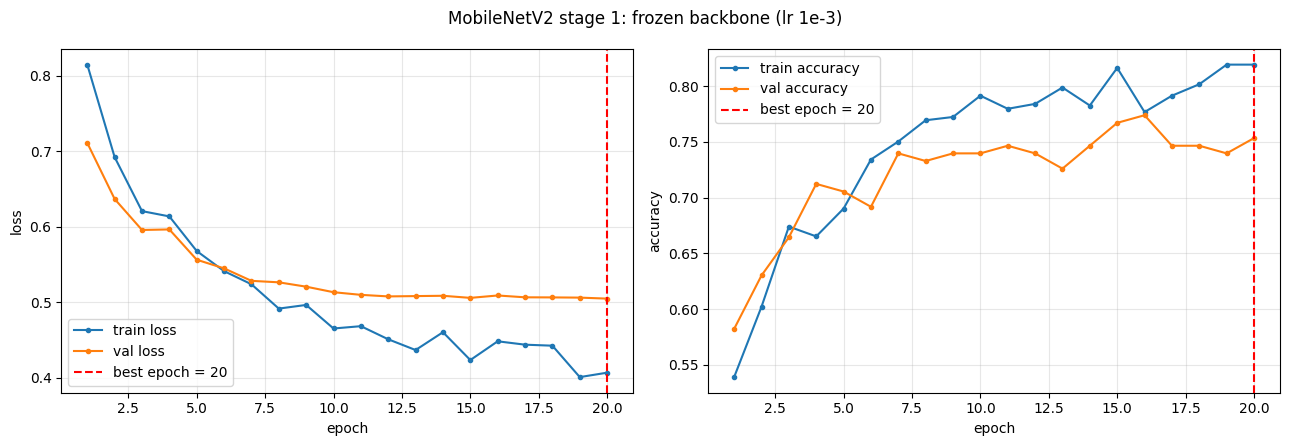

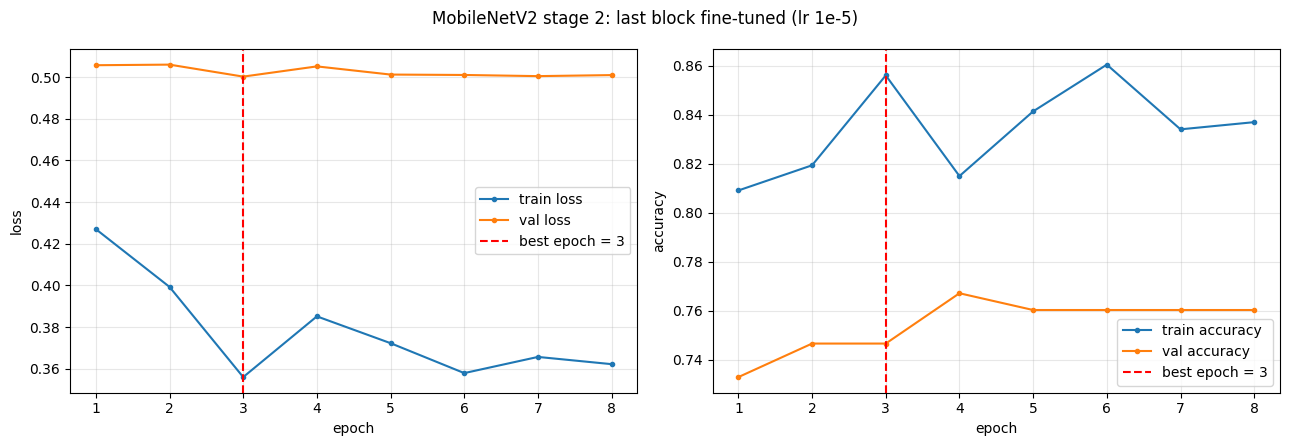


Stage 1 best epoch 20 (val_loss 0.5049) | Stage 2 best epoch 3 (val_loss 0.5002) | run 53079fbe1a8649328a8d3451283d3fc9
🏃 View run mobilenetv2_autolog at: https://dagshub.com/bhatti-zayan/23L-0951_A2_Ops.mlflow/#/experiments/1/runs/53079fbe1a8649328a8d3451283d3fc9
🧪 View experiment at: https://dagshub.com/bhatti-zayan/23L-0951_A2_Ops.mlflow/#/experiments/1


In [15]:
LR1, LR2, EP1, EP2 = 1e-3, 1e-5, 20, 20
keras.utils.set_random_seed(SEED)
model, base = build_mobilenet()

mlflow.tensorflow.autolog(log_models=True, log_datasets=False, silent=True)

with mlflow.start_run(run_name="mobilenetv2_autolog") as parent:
    mlflow.set_tags(base_tags("mobilenetv2", "autolog"))      # autolog does NOT add these
    mlflow.log_params({"model": "mobilenetv2", "backbone_weights": "imagenet", "img_size": 224,
                       "batch_size": 32, "augmentation": "mild", "resize": "pad_224",
                       "dropout": 0.3, "lr_stage1": LR1, "lr_stage2": LR2,
                       "unfrozen_from": "block_16_expand", "bn_layers_frozen": True})

    # ---- Stage 1: frozen backbone, train only the head ----
    model.compile(optimizer=keras.optimizers.Adam(LR1), loss="binary_crossentropy", metrics=METRICS())
    s1_names, s1_n = trainable_layers(model, base)
    with mlflow.start_run(run_name="stage1_frozen", nested=True):
        mlflow.set_tags({**base_tags("mobilenetv2", "autolog"), "stage": "1_frozen_backbone"})
        h1 = model.fit(train_ds, validation_data=val_ds, epochs=EP1, verbose=2,
                       callbacks=make_callbacks("mnv2_stage1", es_patience=5, lr_patience=2))

    # ---- Stage 2: unfreeze only the last block, much smaller LR ----
    unfreeze_last_block(base)
    model.compile(optimizer=keras.optimizers.Adam(LR2), loss="binary_crossentropy", metrics=METRICS())
    s2_names, s2_n = trainable_layers(model, base)
    with mlflow.start_run(run_name="stage2_finetune", nested=True):
        mlflow.set_tags({**base_tags("mobilenetv2", "autolog"), "stage": "2_finetune_last_block"})
        h2 = model.fit(train_ds, validation_data=val_ds, epochs=EP2, verbose=2,
                       callbacks=make_callbacks("mnv2_stage2", es_patience=5, lr_patience=2))

    mlflow.tensorflow.autolog(disable=True)   # everything below is logged manually on the parent

    # Trainable-layer lists for each stage (2.3 evidence)
    layer_txt = (f"STAGE 1 (frozen backbone): {s1_n:,} trainable params\n  " + "\n  ".join(s1_names) +
                 f"\n\nSTAGE 2 (last block unfrozen, BN frozen): {s2_n:,} trainable params\n  " + "\n  ".join(s2_names))
    (PROJECT_DIR / "reports" / "mnv2_trainable_layers.txt").write_text(layer_txt)
    mlflow.log_text(layer_txt, "trainable_layers.txt")
    print(layer_txt)

    # Two sets of curves, each with its best epoch marked
    fig1, best1 = plot_curves(h1.history, "MobileNetV2 stage 1: frozen backbone (lr 1e-3)", "mnv2_stage1_curves.png")
    mlflow.log_figure(fig1, "curves/mnv2_stage1_curves.png"); plt.show()
    fig2, best2 = plot_curves(h2.history, "MobileNetV2 stage 2: last block fine-tuned (lr 1e-5)", "mnv2_stage2_curves.png")
    mlflow.log_figure(fig2, "curves/mnv2_stage2_curves.png"); plt.show()

    mlflow.log_metrics({"best_epoch_stage1": best1, "best_epoch_stage2": best2,
                        "best_val_loss_stage1": float(min(h1.history["val_loss"])),
                        "best_val_loss_stage2": float(min(h2.history["val_loss"]))})
    log_common_artifacts()
    log_keras_model(model, "mobilenetv2", sample[:4])
    save_run_id("mobilenetv2", parent.info.run_id)
    print(f"\nStage 1 best epoch {best1} (val_loss {min(h1.history['val_loss']):.4f}) | "
          f"Stage 2 best epoch {best2} (val_loss {min(h2.history['val_loss']):.4f}) | run {parent.info.run_id}")

In [16]:
save_step("Step 12: MobileNetV2 two-stage fine-tuning with autologging (2.3, 3.3)", "03_training.ipynb");

[main f340411] Step 12: MobileNetV2 two-stage fine-tuning with autologging (2.3, 3.3)
 5 files changed, 12 insertions(+), 2 deletions(-)
 create mode 100644 reports/figures/mnv2_stage1_curves.png
 create mode 100644 reports/figures/mnv2_stage2_curves.png
 create mode 100644 reports/mnv2_trainable_layers.txt
To https://github.com/bhatti-zayan/23L-0951_A2_Ops.git
   e0a1dc4..f340411  main -> main
f340411 Step 12: MobileNetV2 two-stage fine-tuning with autologging (2.3, 3.3)


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 8 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


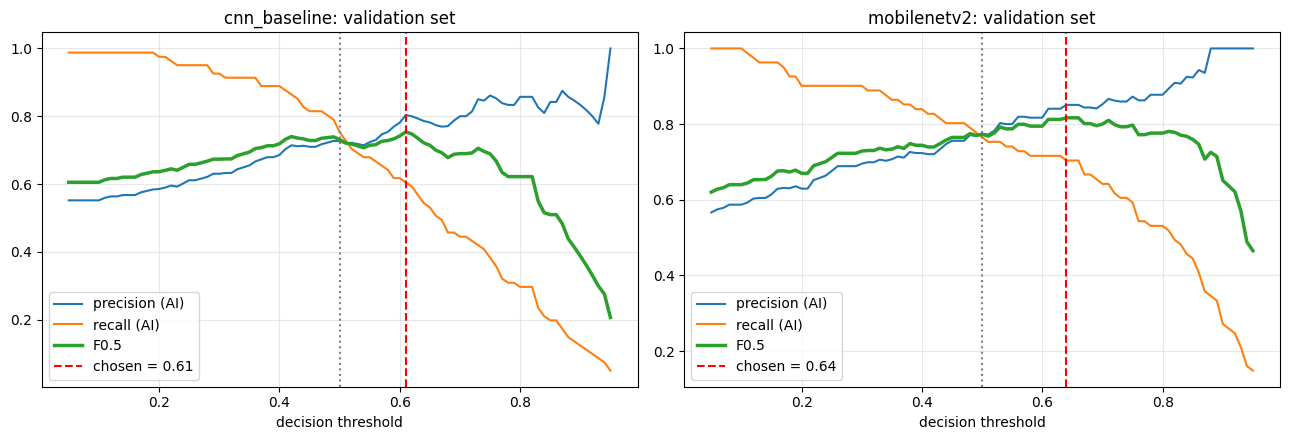

Chosen thresholds (validation, max F0.5): {'cnn_baseline': 0.61, 'mobilenetv2': 0.64}


In [17]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)

run_ids = json.loads(RUN_IDS_FILE.read_text())
models = {"cnn_baseline": keras.saving.load_model(CKPT_DIR / "cnn_baseline_final.keras"),
          "mobilenetv2":  keras.saving.load_model(CKPT_DIR / "mobilenetv2_final.keras")}
val_df, test_df = pd.read_csv(SPLITS / "val.csv"), pd.read_csv(SPLITS / "test.csv")
y_val, y_test = val_df["label"].values, test_df["label"].values

# val/test datasets are NOT shuffled, so prediction order == CSV row order
probs = {n: {"val": m.predict(val_ds, verbose=0).ravel(),
             "test": m.predict(test_ds, verbose=0).ravel()} for n, m in models.items()}
assert all(len(p["val"]) == len(y_val) and len(p["test"]) == len(y_test) for p in probs.values())

def pick_threshold(y, p, beta=0.5):
    grid = np.round(np.arange(0.05, 0.96, 0.01), 2)
    scores = np.array([fbeta_score(y, (p >= t).astype(int), beta=beta, zero_division=0) for t in grid])
    return float(grid[int(np.argmax(scores))]), grid, scores

def metrics_at(y, p, t):
    yp = (p >= t).astype(int)
    return {"accuracy": accuracy_score(y, yp), "precision": precision_score(y, yp, zero_division=0),
            "recall": recall_score(y, yp, zero_division=0), "f1": f1_score(y, yp, zero_division=0),
            "roc_auc": roc_auc_score(y, p)}

# Figure: how precision / recall / F0.5 change with the threshold (validation only)
fig_t, axes = plt.subplots(1, 2, figsize=(13, 4.5))
thresholds = {}
for ax, name in zip(axes, models):
    t, grid, f05 = pick_threshold(y_val, probs[name]["val"]); thresholds[name] = t
    prec = [precision_score(y_val, (probs[name]["val"] >= g).astype(int), zero_division=0) for g in grid]
    rec  = [recall_score(y_val, (probs[name]["val"] >= g).astype(int)) for g in grid]
    ax.plot(grid, prec, label="precision (AI)"); ax.plot(grid, rec, label="recall (AI)")
    ax.plot(grid, f05, lw=2.5, label="F0.5")
    ax.axvline(t, color="red", ls="--", label=f"chosen = {t:.2f}"); ax.axvline(0.5, color="gray", ls=":")
    ax.set_title(f"{name}: validation set"); ax.set_xlabel("decision threshold"); ax.legend(); ax.grid(alpha=.3)
fig_t.tight_layout(); fig_t.savefig(FIG_DIR / "threshold_selection.png", dpi=110, bbox_inches="tight"); plt.show()
print("Chosen thresholds (validation, max F0.5):", thresholds)

🏃 View run cnn_baseline_manual at: https://dagshub.com/bhatti-zayan/23L-0951_A2_Ops.mlflow/#/experiments/1/runs/2e262f2bf3a54cbc889058ee0fa2e0b8
🧪 View experiment at: https://dagshub.com/bhatti-zayan/23L-0951_A2_Ops.mlflow/#/experiments/1


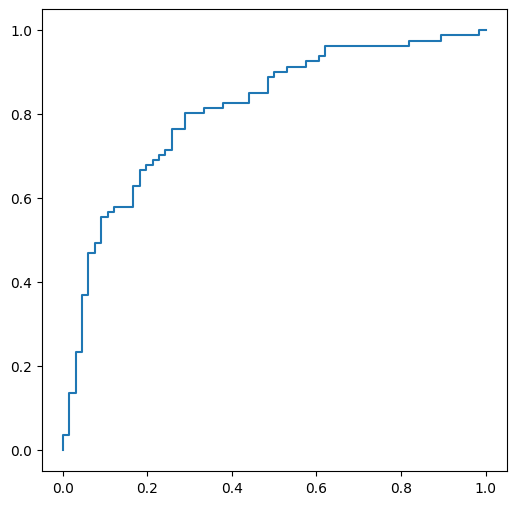

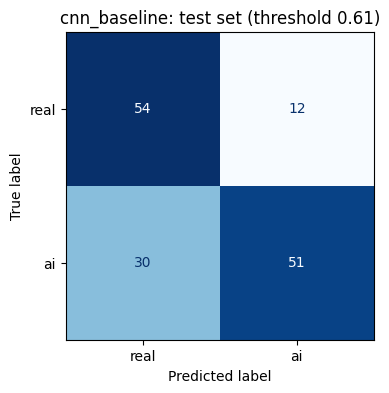

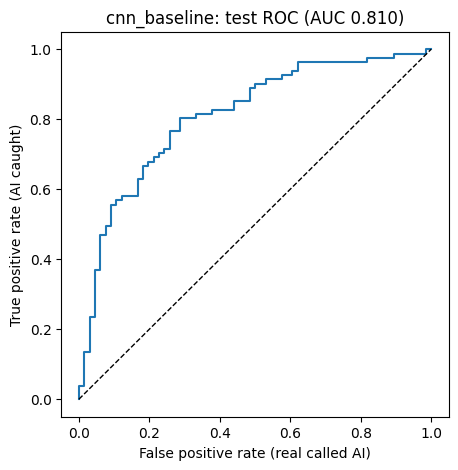

🏃 View run mobilenetv2_autolog at: https://dagshub.com/bhatti-zayan/23L-0951_A2_Ops.mlflow/#/experiments/1/runs/53079fbe1a8649328a8d3451283d3fc9
🧪 View experiment at: https://dagshub.com/bhatti-zayan/23L-0951_A2_Ops.mlflow/#/experiments/1


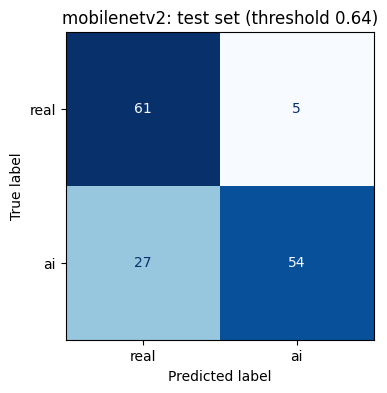

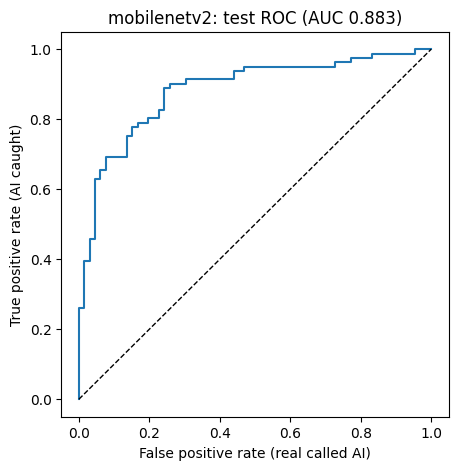

,threshold,accuracy,precision,recall,f1,roc_auc
model,,,,,,
cnn_baseline,0.61,0.7143,0.8095,0.6296,0.7083,0.8103
mobilenetv2,0.64,0.7823,0.9153,0.6667,0.7714,0.8825


In [18]:
rows = []
fig_roc, ax_roc = plt.subplots(figsize=(6, 6))
for name in models:
    t = thresholds[name]
    p_val, p_test = probs[name]["val"], probs[name]["test"]
    test_m, val_m, test_05 = metrics_at(y_test, p_test, t), metrics_at(y_val, p_val, t), metrics_at(y_test, p_test, 0.5)
    rows.append({"model": name, "threshold": t, **{k: round(v, 4) for k, v in test_m.items()}})

    yp = (p_test >= t).astype(int)
    fig_cm, ax = plt.subplots(figsize=(4.5, 4))
    ConfusionMatrixDisplay(confusion_matrix(y_test, yp, labels=[0, 1]),
                           display_labels=["real", "ai"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name}: test set (threshold {t:.2f})")
    fig_cm.savefig(FIG_DIR / f"cm_{name}.png", dpi=110, bbox_inches="tight")

    fpr, tpr, _ = roc_curve(y_test, p_test)
    ax_roc.plot(fpr, tpr, label=f"{name} (AUC = {test_m['roc_auc']:.3f})")
    fig_r, ar = plt.subplots(figsize=(5, 5))
    ar.plot(fpr, tpr); ar.plot([0, 1], [0, 1], "k--", lw=1)
    ar.set_xlabel("False positive rate (real called AI)"); ar.set_ylabel("True positive rate (AI caught)")
    ar.set_title(f"{name}: test ROC (AUC {test_m['roc_auc']:.3f})")
    fig_r.savefig(FIG_DIR / f"roc_{name}.png", dpi=110, bbox_inches="tight")

    pred_path = PROJECT_DIR / "reports" / f"test_predictions_{name}.csv"
    test_df.assign(p_ai=p_test, pred=yp, correct=(yp == y_test)).to_csv(pred_path, index=False)

    with mlflow.start_run(run_id=run_ids[name]):          # add to the SAME training run
        mlflow.log_metrics({f"test_{k}": v for k, v in test_m.items()}
                           | {f"val_{k}_at_threshold": v for k, v in val_m.items()}
                           | {f"test_{k}_at_0.5": v for k, v in test_05.items()}
                           | {"decision_threshold": t})
        mlflow.set_tag("threshold_rule", "max F0.5 on validation")
        mlflow.log_figure(fig_cm, "evaluation/confusion_matrix.png")
        mlflow.log_figure(fig_r, "evaluation/roc_curve.png")
        mlflow.log_artifact(str(pred_path), "evaluation")
    plt.show()

ax_roc.plot([0, 1], [0, 1], "k--", lw=1); ax_roc.legend()
ax_roc.set_xlabel("False positive rate"); ax_roc.set_ylabel("True positive rate"); ax_roc.set_title("Test ROC: both models")
fig_roc.savefig(FIG_DIR / "roc_both_models.png", dpi=110, bbox_inches="tight"); plt.show()

metric_table = pd.DataFrame(rows).set_index("model")
display(metric_table); metric_table.to_csv(PROJECT_DIR / "reports" / "test_metrics.csv")

Misclassified: 32 of 147 test images


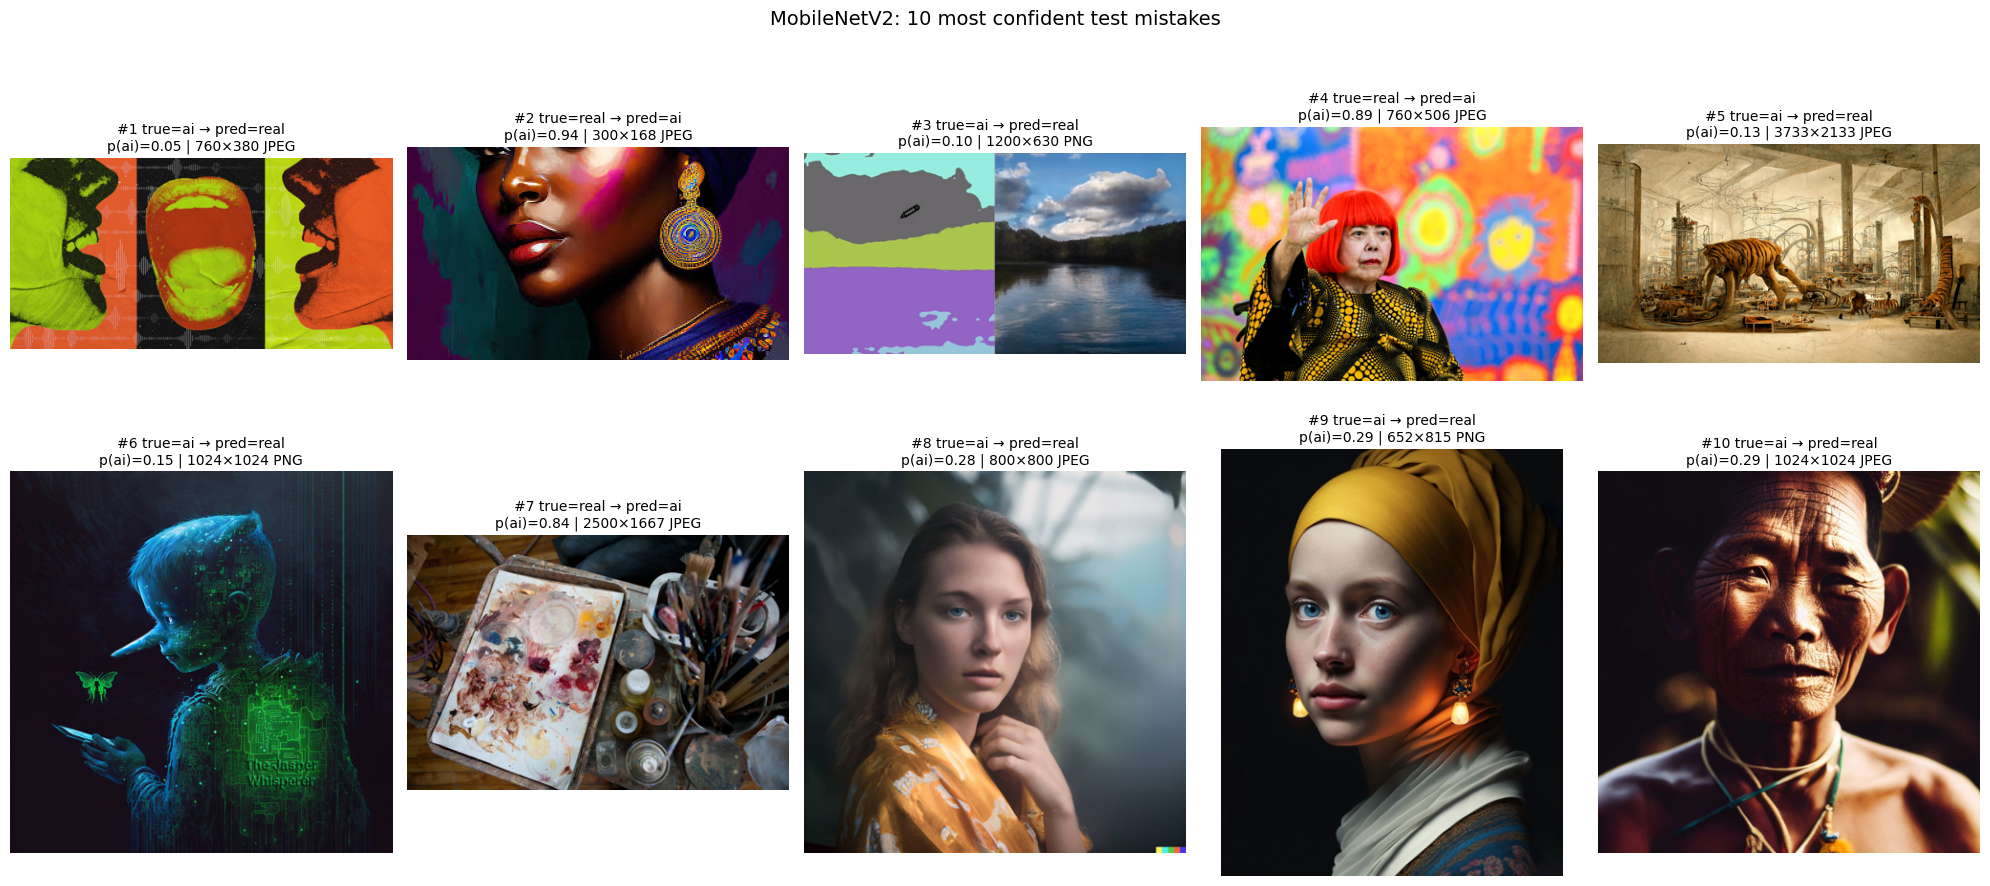

,rel_path,class,p_ai,width,height,format,mode,file_size
0,AiArtData/AiArtData/240201-airec-main-ksp-5625...,ai,0.052233,760,380,JPEG,RGB,184317
1,RealArt/RealArt/images108.jpg,real,0.936465,300,168,JPEG,RGB,12216
2,AiArtData/AiArtData/nvidia-ai-scribbles-realis...,ai,0.100547,1200,630,PNG,RGB,400344
3,RealArt/RealArt/231019-Yayoi-Kusama-ew-337p-64...,real,0.886448,760,506,JPEG,RGB,159944
4,AiArtData/AiArtData/tiger4.jpg,ai,0.125553,3733,2133,JPEG,RGB,3857651
5,AiArtData/AiArtData/188PNRFVDD0f9aTkdz34WYA.png,ai,0.147217,1024,1024,PNG,RGBA,1666412
6,RealArt/RealArt/_MG_5812.jpg,real,0.841756,2500,1667,JPEG,RGB,890920
7,AiArtData/AiArtData/earing-a-yellow-kimono-in-...,ai,0.279889,800,800,JPEG,RGB,48900
8,AiArtData/AiArtData/Julian-van-Dieken_A-Girl-W...,ai,0.292303,652,815,PNG,RGB,446572
9,AiArtData/AiArtData/3e9bc32a-1d77-4f0a-b0df-19...,ai,0.292740,1024,1024,JPEG,RGB,114819


In [19]:
audit = pd.read_csv("reports/audit/audit_table.csv")[["rel_path", "width", "height", "format", "mode", "file_size"]]
pred = pd.read_csv(PROJECT_DIR / "reports" / "test_predictions_mobilenetv2.csv").merge(audit, on="rel_path")
wrong = pred[~pred["correct"]].assign(confidence=lambda d: (d.p_ai - 0.5).abs()) \
                              .sort_values("confidence", ascending=False)
print(f"Misclassified: {len(wrong)} of {len(pred)} test images")

top10 = wrong.head(10).reset_index(drop=True)
fig, axes = plt.subplots(2, 5, figsize=(20, 9))
for ax, r in zip(axes.flat, top10.itertuples()):
    with Image.open(RAW_LOCAL / r.rel_path) as im:
        im = im.convert("RGB"); im.thumbnail((400, 400)); ax.imshow(im)
    ax.set_title(f"#{r.Index+1} true={r._2} → pred={'ai' if r.pred else 'real'}\n"
                 f"p(ai)={r.p_ai:.2f} | {r.width}×{r.height} {r.format}", fontsize=10)
    ax.axis("off")
fig.suptitle("MobileNetV2: 10 most confident test mistakes", fontsize=14); fig.tight_layout()
fig.savefig(FIG_DIR / "error_analysis_top10.png", dpi=110, bbox_inches="tight"); plt.show()
display(top10[["rel_path", "class", "p_ai", "width", "height", "format", "mode", "file_size"]])
top10.to_csv(PROJECT_DIR / "reports" / "error_analysis_top10.csv", index=False)

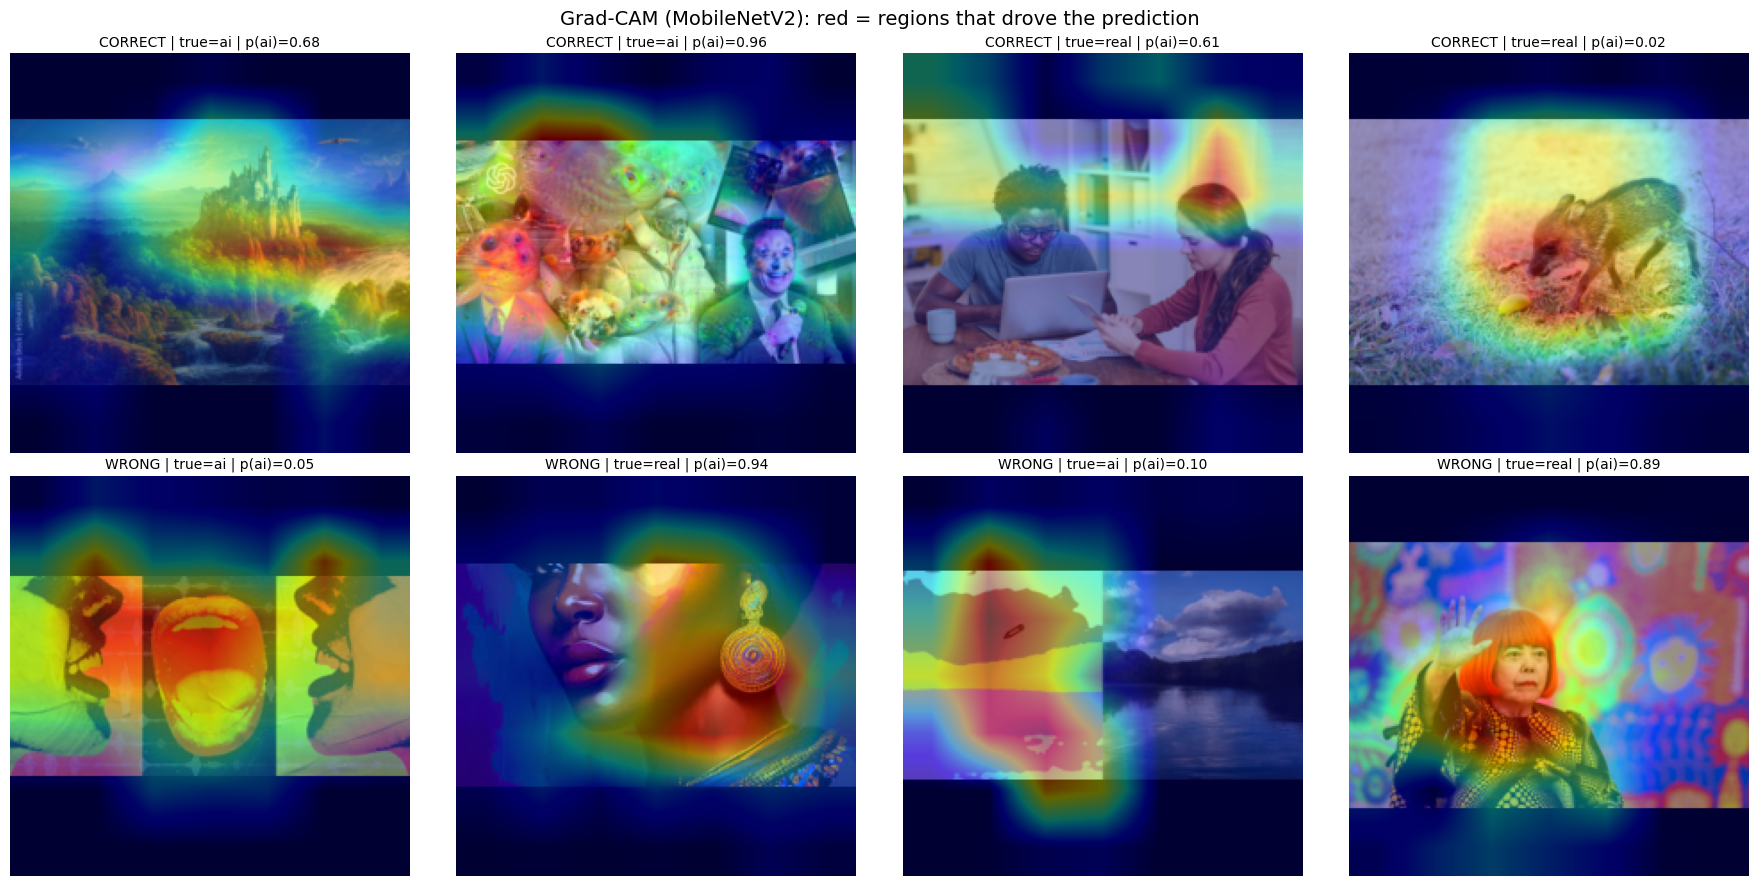

🏃 View run mobilenetv2_autolog at: https://dagshub.com/bhatti-zayan/23L-0951_A2_Ops.mlflow/#/experiments/1/runs/53079fbe1a8649328a8d3451283d3fc9
🧪 View experiment at: https://dagshub.com/bhatti-zayan/23L-0951_A2_Ops.mlflow/#/experiments/1


In [20]:
mnv2 = models["mobilenetv2"]
backbone = next(l for l in mnv2.layers if isinstance(l, keras.Model))   # the nested MobileNetV2

def gradcam(img_0_255):
    """Heat map of where the model looked, for the class it predicted."""
    x = mnv2.get_layer("mobilenet_preprocess")(img_0_255[None])
    with tf.GradientTape() as tape:
        feats = backbone(x, training=False)                 # (1, 7, 7, 1280) last conv features
        tape.watch(feats)
        p = mnv2.get_layer("p_ai")(mnv2.get_layer("gap")(feats))[0, 0]
        target = p if p >= thresholds["mobilenetv2"] else 1 - p
    grads = tape.gradient(target, feats)[0]
    weights = tf.reduce_mean(grads, axis=(0, 1))            # importance of each feature map
    cam = tf.nn.relu(tf.reduce_sum(feats[0] * weights, axis=-1))
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    return tf.image.resize(cam[..., None], (224, 224)).numpy()[..., 0], float(p)

right = pred[pred["correct"]]
picks = pd.concat([right[right.label == 1].head(2), right[right.label == 0].head(2),
                   wrong.head(4)]).reset_index(drop=True)
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, r in zip(axes.flat, picks.itertuples()):
    img = data.load_image(str(RAW_LOCAL / r.rel_path)).numpy().astype("float32")
    cam, p = gradcam(img)
    ax.imshow(img.astype("uint8")); ax.imshow(cam, cmap="jet", alpha=0.4)
    ax.set_title(f"{'CORRECT' if r.correct else 'WRONG'} | true={r._2} | p(ai)={p:.2f}", fontsize=10)
    ax.axis("off")
fig.suptitle("Grad-CAM (MobileNetV2): red = regions that drove the prediction", fontsize=14)
fig.tight_layout(); fig.savefig(FIG_DIR / "gradcam.png", dpi=110, bbox_inches="tight"); plt.show()
with mlflow.start_run(run_id=run_ids["mobilenetv2"]):
    mlflow.log_artifact(str(FIG_DIR / "gradcam.png"), "evaluation")
    mlflow.log_artifact(str(FIG_DIR / "error_analysis_top10.png"), "evaluation")

In [21]:
save_step("Step 13 outputs: test metrics, predictions, error analysis", "03_training.ipynb");

[main 8713edc] Step 13 outputs: test metrics, predictions, error analysis
 13 files changed, 311 insertions(+), 1 deletion(-)
 create mode 100644 reports/error_analysis_top10.csv
 create mode 100644 reports/figures/cm_cnn_baseline.png
 create mode 100644 reports/figures/cm_mobilenetv2.png
 create mode 100644 reports/figures/error_analysis_top10.png
 create mode 100644 reports/figures/gradcam.png
 create mode 100644 reports/figures/roc_both_models.png
 create mode 100644 reports/figures/roc_cnn_baseline.png
 create mode 100644 reports/figures/roc_mobilenetv2.png
 create mode 100644 reports/figures/threshold_selection.png
 create mode 100644 reports/test_metrics.csv
 create mode 100644 reports/test_predictions_cnn_baseline.csv
 create mode 100644 reports/test_predictions_mobilenetv2.csv
To https://github.com/bhatti-zayan/23L-0951_A2_Ops.git
   f340411..8713edc  main -> main
8713edc Step 13 outputs: test metrics, predictions, error analysis


In [22]:
import keras_tuner as kt

(fx_tr, fy_tr), _ = keras.datasets.fashion_mnist.load_data()
fx_tr = fx_tr.astype("float32") / 255.0

def build_toy(hp):
    m = keras.Sequential([
        keras.Input((28, 28)), layers.Flatten(),
        layers.Dense(hp.Int("units", 32, 256, step=32), activation="relu"),
        layers.Dense(10, activation="softmax")])
    m.compile(optimizer=keras.optimizers.Adam(hp.Float("learning_rate", 1e-4, 1e-2, sampling="log")),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def trials_table(tuner, score_name):
    rows = [{"trial": t.trial_id, **t.hyperparameters.values, score_name: t.score}
            for t in tuner.oracle.trials.values() if t.score is not None]
    return pd.DataFrame(rows)

toy_tuner = kt.RandomSearch(build_toy, objective="val_accuracy", max_trials=8, seed=SEED,
                            directory=str(TUNER_DIR), project_name="toy_fashion_mnist", overwrite=False)
toy_tuner.search(fx_tr, fy_tr, validation_split=0.1, epochs=3, batch_size=256, verbose=1)

toy_df = trials_table(toy_tuner, "val_accuracy").sort_values("val_accuracy", ascending=False)
display(toy_df.round(4)); toy_df.to_csv(PROJECT_DIR / "reports" / "tuner_toy_results.csv", index=False)
print("Best toy settings:", toy_tuner.get_best_hyperparameters(1)[0].values)

Trial 8 Complete [00h 00m 07s]
val_accuracy: 0.8341666460037231

Best val_accuracy So Far: 0.8706666827201843
Total elapsed time: 00h 01m 09s


,trial,units,learning_rate,val_accuracy
5,5,256,0.0017,0.8707
2,2,256,0.0005,0.8555
1,1,128,0.0003,0.8478
4,4,128,0.0003,0.8442
6,6,256,0.0002,0.8410
7,7,256,0.0001,0.8342
0,0,192,0.0001,0.8320
3,3,160,0.0001,0.8268


Best toy settings: {'units': 256, 'learning_rate': 0.001715074355925934}


In [23]:
def build_vg(hp):
    lr         = hp.Choice("learning_rate", [1e-3, 3e-4, 1e-4, 3e-5])
    dropout    = hp.Choice("dropout", [0.2, 0.3, 0.5])
    n_unfrozen = hp.Choice("unfrozen_layers", [0, 10, 20, 40])
    m, base = build_mobilenet(dropout=dropout)
    if n_unfrozen > 0:
        base.trainable = True
        first = len(base.layers) - n_unfrozen
        for i, l in enumerate(base.layers):
            l.trainable = i >= first and not isinstance(l, layers.BatchNormalization)
    m.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy", metrics=METRICS())
    return m

vg_tuner = kt.RandomSearch(build_vg, objective=kt.Objective("val_loss", direction="min"),
                           max_trials=10, seed=SEED, directory=str(TUNER_DIR),
                           project_name="visionguard_mnv2", overwrite=False)
vg_tuner.search_space_summary()
vg_tuner.search(train_ds, validation_data=val_ds, epochs=12, verbose=2,
                callbacks=[callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)])

Trial 10 Complete [00h 00m 41s]
val_loss: 0.6879566311836243

Best val_loss So Far: 0.3684978187084198
Total elapsed time: 00h 06m 39s


In [24]:
vg_df = trials_table(vg_tuner, "val_loss").sort_values("val_loss")
display(vg_df.round(4)); vg_df.to_csv(PROJECT_DIR / "reports" / "tuner_visionguard_results.csv", index=False)

# Rough importance: how much the AVERAGE val_loss changes across the values of each setting
print("Mean val_loss per value (bigger spread = setting mattered more):")
spread = {}
for hp_name in ["learning_rate", "dropout", "unfrozen_layers"]:
    means = vg_df.groupby(hp_name)["val_loss"].mean().round(4)
    spread[hp_name] = float(means.max() - means.min())
    print(f"\n{hp_name}:\n{means.to_string()}")
print("\nSpread (max - min of means):", {k: round(v, 4) for k, v in spread.items()})

best_hp = vg_tuner.get_best_hyperparameters(1)[0].values
print("\nBest VisionGuard settings:", best_hp)

with mlflow.start_run(run_name="keras_tuner_search"):
    mlflow.set_tags(base_tags("mobilenetv2", "keras_tuner"))
    mlflow.log_params({f"best_{k}": v for k, v in best_hp.items()} |
                      {"tuner": "RandomSearch", "max_trials": 10, "epochs_per_trial": 12})
    mlflow.log_metric("best_trial_val_loss", float(vg_df["val_loss"].min()))
    mlflow.log_artifact(str(PROJECT_DIR / "reports" / "tuner_visionguard_results.csv"), "tuner")
    mlflow.log_artifact(str(PROJECT_DIR / "reports" / "tuner_toy_results.csv"), "tuner")

,trial,learning_rate,dropout,unfrozen_layers,val_loss
5,05,0.0003,0.3,40,0.3685
3,03,0.0000,0.2,40,0.4170
1,01,0.0003,0.5,10,0.4328
6,06,0.0003,0.3,10,0.4407
0,00,0.0001,0.2,10,0.4435
8,08,0.0001,0.5,10,0.4788
4,04,0.0010,0.3,0,0.5259
7,07,0.0010,0.2,20,0.6871
2,02,0.0010,0.5,20,0.6878
9,09,0.0010,0.2,40,0.6880


Mean val_loss per value (bigger spread = setting mattered more):

learning_rate:
learning_rate
0.00003    0.4170
0.00010    0.4611
0.00030    0.4140
0.00100    0.6472

dropout:
dropout
0.2    0.5589
0.3    0.4450
0.5    0.5331

unfrozen_layers:
unfrozen_layers
0     0.5259
10    0.4489
20    0.6874
40    0.4912

Spread (max - min of means): {'learning_rate': 0.2332, 'dropout': 0.1139, 'unfrozen_layers': 0.2385}

Best VisionGuard settings: {'learning_rate': 0.0003, 'dropout': 0.3, 'unfrozen_layers': 40}
🏃 View run keras_tuner_search at: https://dagshub.com/bhatti-zayan/23L-0951_A2_Ops.mlflow/#/experiments/1/runs/0aece81998054600bba07a51c0acabea
🧪 View experiment at: https://dagshub.com/bhatti-zayan/23L-0951_A2_Ops.mlflow/#/experiments/1


In [ ]:
save_step("Step 14: Keras Tuner toy + VisionGuard search (2.7)", "03_training.ipynb");